Mean Waktu Tunggu (μ) : 26.50 menit
Std Dev (σ)            : 7.20 menit

=== HASIL ANALISIS RISIKO MONTE CARLO ===
Batas Maksimum SOP     : 30.0 menit
Skenario Melampaui SOP : 0 dari 10000 simulasi
Probabilitas Terlambat : 0.00%


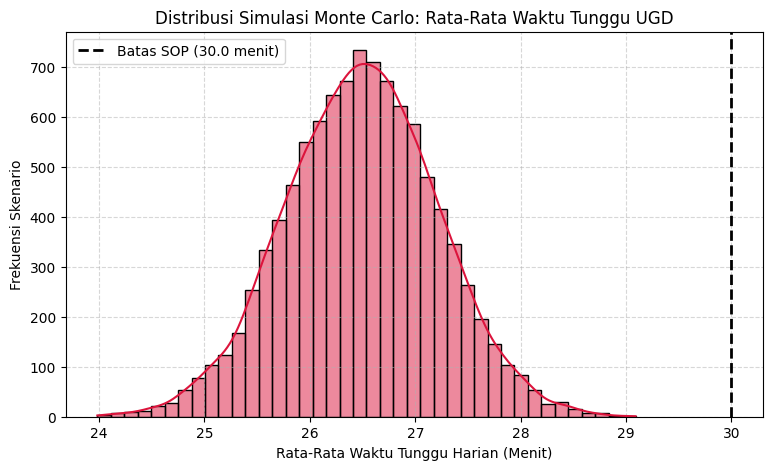

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# ==========================================
# STEP 1: MENGATUR SEED BERDASARKAN NIM
# ==========================================
NIM = 301230043  # Ganti dengan NIM kamu
np.random.seed(NIM)

# ==========================================
# STEP 2: PARAMETER DATASET HISTORIS
# ==========================================
# Jika sudah ada dataset Kaggle, ganti nilai mu dan sigma
# dengan hasil mean() dan std() dari dataset tersebut.
mu = 26.5       # Rata-rata waktu tunggu historis (menit)
sigma = 7.2     # Standar deviasi historis (menit)

print(f"Mean Waktu Tunggu (μ) : {mu:.2f} menit")
print(f"Std Dev (σ)            : {sigma:.2f} menit")

# ==========================================
# STEP 3: PROSES SIMULASI MONTE CARLO
# ==========================================
num_simulations = 10000  # Total 10.000 iterasi
pasien_per_hari = 100    # Sampel 100 pasien UGD per hari

# Pembangkitan data acak berdistribusi normal
simulated_wait_times = np.random.normal(mu, sigma, (num_simulations, pasien_per_hari))

# Menhitung rata-rata waktu tunggu harian tiap simulasi
daily_avg_wait_time = np.mean(simulated_wait_times, axis=1)

# ==========================================
# STEP 4: ANALISIS RISIKO & PROBABILITAS
# ==========================================
sop_threshold = 30.0  # Batas maksimum SOP (30 menit)

# Hitung berapa simulasi yang melampaui SOP
exceeded_scenarios = np.sum(daily_avg_wait_time > sop_threshold)
probability_exceeded = (exceeded_scenarios / num_simulations) * 100

print("\n=== HASIL ANALISIS RISIKO MONTE CARLO ===")
print(f"Batas Maksimum SOP     : {sop_threshold} menit")
print(f"Skenario Melampaui SOP : {exceeded_scenarios} dari {num_simulations} simulasi")
print(f"Probabilitas Terlambat : {probability_exceeded:.2f}%")

# ==========================================
# STEP 5: VISUALISASI HASIL SIMULASI
# ==========================================
plt.figure(figsize=(9, 5))
sns.histplot(daily_avg_wait_time, bins=40, kde=True, color='crimson')

# Garis ambang batas SOP
plt.axvline(x=sop_threshold, color='black', linestyle='--', linewidth=2,
            label=f'Batas SOP ({sop_threshold} menit)')

plt.title("Distribusi Simulasi Monte Carlo: Rata-Rata Waktu Tunggu UGD")
plt.xlabel("Rata-Rata Waktu Tunggu Harian (Menit)")
plt.ylabel("Frekuensi Skenario")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()